# 01 · Week 1: validating the NumPy LIF against Shiu et al. (Brian2)
A connectome-constrained leaky integrate-and-fire (LIF) simulation of the whole FlyWire v630 brain (127,400 neurons), reimplemented in NumPy (`sim/lif_numpy.py`) and compared with the authors' Brian2 code. Stimulus: the 21 sugar gustatory receptor neurons at 150 Hz Poisson for 1 s. Readout: MN9, the proboscis-extension motor neuron.

This notebook only loads saved per-neuron rates; it does not re-run either simulator.
- `results/flywire_sugar_brian2_fresh.npy`: Brian2 (Shiu code), 3 trials × 127,400 neurons, Hz
- `results/flywire_sugar_numpy_b2sched.npy`: NumPy with Brian2's step order, mean of 3 trials, Hz

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
R = ROOT / 'results'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
ids = pd.read_csv(ROOT/'third_party/Drosophila_brain_model/2023_03_23_completeness_630_final.csv', index_col=0).index.to_numpy()
b2 = np.load(R/'flywire_sugar_brian2_fresh.npy'); npy = np.load(R/'flywire_sugar_numpy_b2sched.npy')
MN9 = 720575940660219265  # left MN9, Shiu et al. readout
i = int(np.flatnonzero(ids == MN9)[0])
print(f'neurons: {len(ids):,}')
print(f'MN9  Brian2: {b2[:, i].mean():.1f} ± {b2[:, i].std():.1f} Hz (3 trials)   NumPy: {npy[i]:.1f} Hz')
print(f'active neurons  Brian2: {(b2.mean(0) > 0).sum()}   NumPy: {(npy > 0).sum()}')

neurons: 127,400
MN9  Brian2: 81.3 ± 0.9 Hz (3 trials)   NumPy: 83.4 Hz
active neurons  Brian2: 392   NumPy: 434


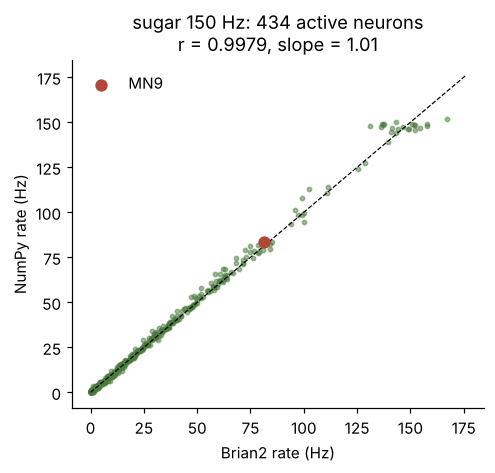

In [3]:
m = b2.mean(0); act = (m > 0) | (npy > 0)
r = np.corrcoef(m[act], npy[act])[0, 1]; slope = np.polyfit(m[act], npy[act], 1)[0]
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(m[act], npy[act], s=8, alpha=.5, color='#4a7a3d')
ax.scatter([m[i]], [npy[i]], s=50, color='#b0483a', label='MN9', zorder=3)
lim = max(m.max(), npy.max()) * 1.05; ax.plot([0, lim], [0, lim], 'k--', lw=.8)
ax.set(xlabel='Brian2 rate (Hz)', ylabel='NumPy rate (Hz)', title=f'sugar 150 Hz: {act.sum()} active neurons\nr = {r:.4f}, slope = {slope:.2f}')
ax.legend(frameon=False); plt.tight_layout()

**Reading it:** the active neurons lie on the identity line (correlation and slope in the title). Week 1's open item was NumPy sugar→MN9 running 13% hot (105.7 vs 93.3 Hz in the Week 1 report). After Week 1 the simulator was changed to Brian2's per-step order and integrator and to block input during refractoriness (`schedule='brian2'`, the default in `run_trial`; commit `03979ff`). This saved pair is the reference used from Week 2 on: MN9 83.4 Hz (NumPy) vs 81.3 ± 0.9 Hz (Brian2, a fresh 3-trial run), so the gap is now about 3%. The Brian2 rate differs from the Week 1 report's 93.3 Hz because it is a separate reference run; compare the two simulators within each pair, not across them.

Week 1 behavioral checks (from `docs/week1_report.html`, before the step-order fix): sugar→MN9 105.7 Hz (Brian2 93.3 ± 3.2, chetaslua's post 78), sugar+bitter→MN9 2.7 Hz (suppressed, as in the paper), water 13 Hz.

In [4]:
c = pd.read_csv(R/'flywire/w2d1_flywire_control.csv')
print('Week 2 starting point: FlyWire v783 run exactly as published (no calibration)')
c.groupby('word')[['stim_active', 'mn9_stim_Hz', 'tail_brain', 'persistent']].mean(numeric_only=False).round(1)

Week 2 starting point: FlyWire v783 run exactly as published (no calibration)


,stim_active,mn9_stim_Hz,tail_brain,persistent
word,,,,
hot,8258.0,0.0,7881.0,1.0
looming,1318.0,0.0,0.0,0.0
none,0.0,0.0,0.0,0.0
sound,583.0,0.0,0.0,0.0
sugar,346.0,83.0,0.0,0.0
vinegar,8409.5,0.0,7848.0,1.0


The last column is why Week 2 existed: in the published model, vinegar and hot leave ~7,900 neurons firing after the stimulus ends (a persistent attractor). Week 2 traced it to the cholinergic eLN→PN chemical loop and replaced it with eLN–PN gap junctions (Yaksi & Wilson 2010). See `02_translator.ipynb`.